1. Setup những thứ cần thiết cho thí nghiệm

In [ ]:
import torch
import time
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# khởi tạo hàm Gaussian_2D và debug dữ liệu
U = np.array([0,0])
C = np.array([
    [0.3,-0.5],
    [-0.5,2]
  ])
# Gaussian 2D
def Gaussian_2D(x):
  x = np.array(x)
  k = x - U # tính x - U trước
  he_so_nhan = 1/(2 * np.pi * np.sqrt(np.linalg.det(C)))
  return he_so_nhan * np.exp(-0.5 * k.T @ np.linalg.inv(C) @ k)
def gen_data_set(n = 1000):
  print(n)
  x1 = np.random.uniform(-2,2,n)
  x2 = np.random.uniform(-4,4,n)
  x = np.column_stack((x1,x2))
  print("x: ",x[:10])
  y = np.array([])
  for x in x:
    y = np.append(y,Gaussian_2D(x))
  print("Y: ",y[:10])
  return x1,x2,y
np.random.seed(42)
x1,x2,y = gen_data_set()

1000
x:  [[-0.50183952 -2.51893657]
 [ 1.80285723  0.33520758]
 [ 0.92797577  2.98356669]
 [ 0.39463394  1.85779909]
 [-1.37592544  2.45248918]
 [-1.37602192  1.27026693]
 [-1.76766555  1.53821252]
 [ 1.46470458  2.79356521]
 [ 0.40446005 -2.00265593]
 [ 0.83229031 -0.08460029]]
Y:  [1.41917360e-03 1.00191988e-05 9.69773296e-06 1.37810239e-02
 1.13433499e-02 7.31889518e-03 6.29739291e-04 5.97860887e-08
 9.61287234e-02 4.09825823e-02]


In [ ]:
# Tạo dữ liệu
df = pd.DataFrame({
    "x1":x1,
    "x2":x2,
    "y_real":y,
})
df.to_csv("DataSet.csv", index=False)

df.head()

,x1,x2,y_real
0,-0.501840,-2.518937,0.001419
1,1.802857,0.335208,0.000010
2,0.927976,2.983567,0.000010
3,0.394634,1.857799,0.013781
4,-1.375925,2.452489,0.011343


In [ ]:
# chia tập theo công thức 10% test/ 90% còn lại trong đó có (20% val, 80% train), random seed = 42
df_new = pd.read_csv("DataSet.csv")
print(df_new.head())
print(df_new.shape)

X_df = df_new[["x1","x2"]]
y_df = df_new["y_real"]
print("dữ liệu X: ")
print(X_df.head())
print("=====================================")
print("dữ liệu y: ")
print(y_df.head())
# chia lấy 100 phần tử cho tập test tương ứng 10%
X_temp, X_test, y_temp, y_test = train_test_split(
    X_df, y_df,
    test_size = 0.1,
    random_state=42
)
print("=====================================")
print("Tập test với 100 phần tử")
print("X: ", X_test.shape)
print("y: ", y_test.shape)
print("=====================================")
print("Các phần tử còn lại sau khi trừ đi 100 phần tử của tập test, được gọi là tập Temp")
print("X: ", X_temp.shape)
print("y: ", y_temp.shape)
print("=====================================")

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size = 0.2,
    random_state=42
)

print("Tập val với 180 phần tử (trên tập Temp)")
print("X: ", X_val.shape)
print("y: ", y_val.shape)
print("=====================================")
print("Tập train với 720 phần tử (trên tập Temp)")
print("X: ", X_train.shape)
print("y: ", y_train.shape)

         x1        x2    y_real
0 -0.501840 -2.518937  0.001419
1  1.802857  0.335208  0.000010
2  0.927976  2.983567  0.000010
3  0.394634  1.857799  0.013781
4 -1.375925  2.452489  0.011343
(1000, 3)
dữ liệu X: 
         x1        x2
0 -0.501840 -2.518937
1  1.802857  0.335208
2  0.927976  2.983567
3  0.394634  1.857799
4 -1.375925  2.452489
dữ liệu y: 
0    0.001419
1    0.000010
2    0.000010
3    0.013781
4    0.011343
Name: y_real, dtype: float64
Tập test với 100 phần tử
X:  (100, 2)
y:  (100,)
Các phần tử còn lại sau khi trừ đi 100 phần tử của tập test, được gọi là tập Temp
X:  (900, 2)
y:  (900,)
Tập val với 180 phần tử (trên tập Temp)
X:  (180, 2)
y:  (180,)
Tập train với 720 phần tử (trên tập Temp)
X:  (720, 2)
y:  (720,)


528   -1.774498
278    0.807868
394   -0.636786
258    0.280245
926   -0.925291
Name: x1, dtype: float64
528    2.424207
278   -2.860036
394   -1.303975
258   -3.486329
926    0.705618
Name: x2, dtype: float64


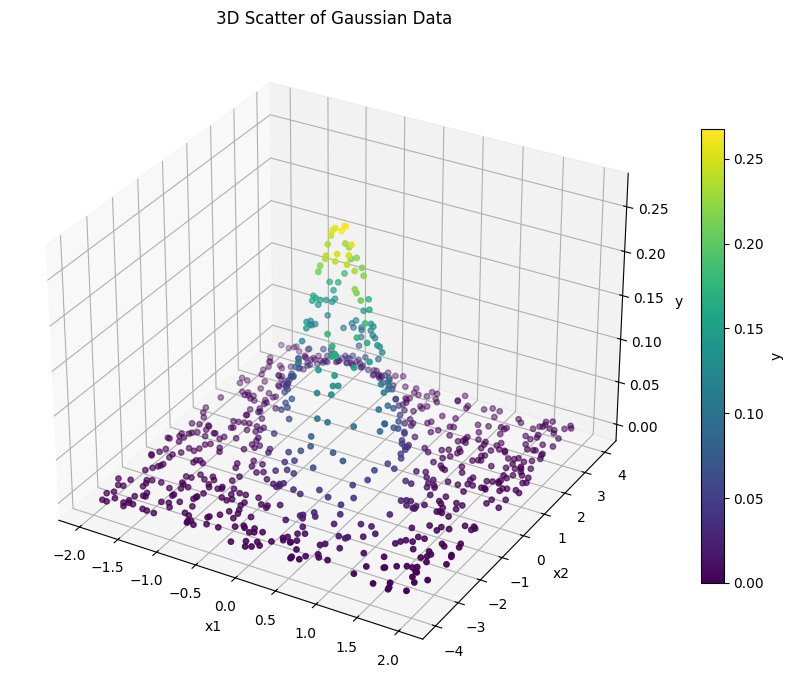

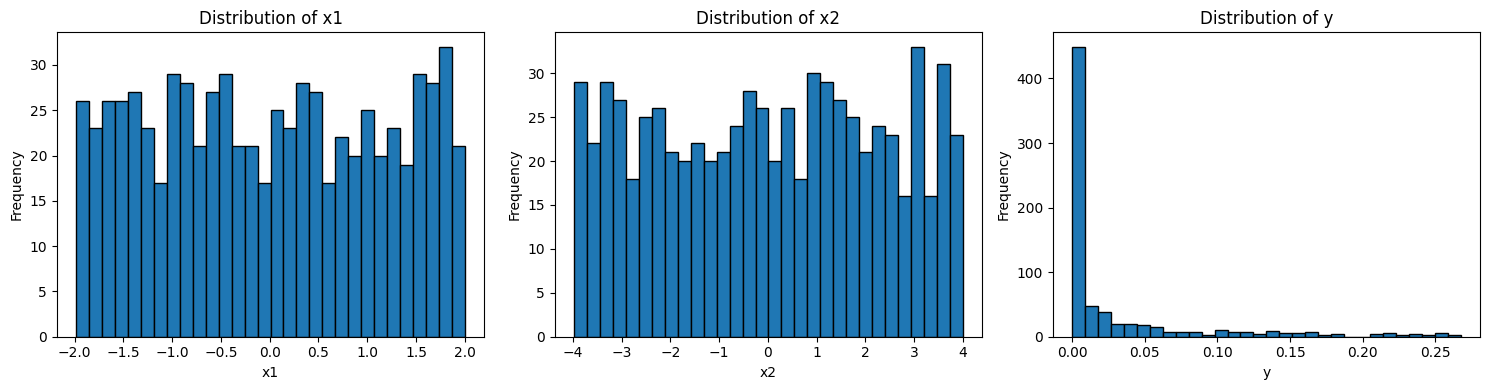

In [ ]:
# vẽ 3D Scatter of Gaussian
X_train_1 = X_train["x1"]
X_train_2 = X_train["x2"]
print(X_train_1.head())
print(X_train_2.head())
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(X_train_1, X_train_2, y_train, c=y_train, cmap="viridis", s=15)

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title("3D Scatter of Gaussian Data")

fig.colorbar(sc, ax=ax, label="y", shrink=0.7)
plt.tight_layout()
plt.show()
# ================================================================
# vẽ sơ đồ phân bố dữ liệu
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(X_train_1, bins=30, edgecolor="black")
axes[0].set_title("Distribution of x1")
axes[0].set_xlabel("x1")
axes[0].set_ylabel("Frequency")

axes[1].hist(X_train_2, bins=30, edgecolor="black")
axes[1].set_title("Distribution of x2")
axes[1].set_xlabel("x2")
axes[1].set_ylabel("Frequency")

axes[2].hist(y_train, bins=30, edgecolor="black")
axes[2].set_title("Distribution of y")
axes[2].set_xlabel("y")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


In [ ]:
# chuyển sang tensor
X_train_tensor = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
print("X_train_tensor (5 phần tử đầu):")
print(X_train_tensor[:5])
print("y_train_tensor (5 phần tử đầu):")
print(y_train_tensor[:5])

X_val_tensor = torch.tensor(X_val.to_numpy(), dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32)

X_test_tensor = torch.tensor(X_test.to_numpy(), dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=len(train_dataset), # 1 batch và toàn bộ data
    shuffle=True
)
print("kiểm tra thử train_loader:")
idx_batch_train_loader_log = 1
for X_batch, y_batch in train_loader:
  print("====================")
  print(idx_batch_train_loader_log,":")
  print("X: ",X_batch.shape)
  print("y: ",y_batch.shape)
  idx_batch_train_loader_log += 1

X_train_tensor (5 phần tử đầu):
tensor([[-1.7745,  2.4242],
        [ 0.8079, -2.8600],
        [-0.6368, -1.3040],
        [ 0.2802, -3.4863],
        [-0.9253,  0.7056]])
y_train_tensor (5 phần tử đầu):
tensor([0.0013, 0.0340, 0.0124, 0.0047, 0.0478])
kiểm tra thử train_loader:
1 :
X:  torch.Size([720, 2])
y:  torch.Size([720])


In [ ]:
# xây dựng mô hình MLP
class MLP(nn.Module):
  def __init__(self, input_size = 2, hiden_sizes = [3], output_size = 1):
    super().__init__()
    layers = []
    prev_input = input_size

    for hiden_size in hiden_sizes:# tạo ra len(hiden_sizes) hiden layers
      layers.append(nn.Linear(prev_input, hiden_size))  # tạo ra hiden_size (với mặc định là 3) perceptron với công thức y = wx + b
      layers.append(nn.ReLU()) # hàm kích hoạt ReLU
      prev_input = hiden_size

    layers.append(nn.Linear(prev_input, output_size))
    self.network = nn.Sequential(*layers)

  def forward(self, x):
      return self.network(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device: ",device)

# cấu hình model tiêu chuẩn
torch.manual_seed(42)
model = MLP(hiden_sizes = [3]).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

device:  cpu


In [ ]:
# Train dữ liệu
def Train(train_loader, X_val_tensor, y_val_tensor, model, optimizer, criterion, file, epochs = 1000):
  min_vali_loss = float("inf")
  best_epoch = 0
  history = {"train": [], "val": []}
  X_val_tensor, y_val_tensor = X_val_tensor.to(device), y_val_tensor.to(device)

  for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
      optimizer.zero_grad() # reset grad về 0 để không bị cộng dồn

      y_pred = model(X_batch).squeeze(-1) # train + predict
      # print(y_pred.shape, y_batch.shape)

      loss = criterion(y_pred, y_batch) # tính loss

      loss.backward() # backpropagation

      optimizer.step() # cặp nhật trọng số

      running_loss += loss.item() * X_batch.size(0) # cộng dồn loss của từng batch

    train_loss = running_loss / len(train_loader.dataset) # tính trung bình loss

    # validation
    model.eval()
    with torch.no_grad():
      y_val_pred = model(X_val_tensor).squeeze(-1)
      val_loss = criterion(y_val_pred, y_val_tensor)

    # lưu lại train_loss và val_loss
    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if (epoch + 1) % 100 == 0:
      print("=" * 50)
      print(f"Epoch {epoch + 1}, "f"Loss: {train_loss:.6f}, "f"Validation MSE: {val_loss.item():.6f}")

    # lưu checkpoint min_vali_loss
    if val_loss.item() < min_vali_loss:
      min_vali_loss = val_loss.item()
      best_epoch = epoch + 1
      torch.save({
              "epoch": epoch + 1,
              "model_state_dict": model.state_dict(),
              "optimizer_state_dict": optimizer.state_dict(),
              "val_loss": min_vali_loss
          }, file)
      if (epoch + 1) % 100 == 0:
        print(f"Đã lưu checkpoint {epoch + 1}")
  return {
        "history": history,
        "best_val_loss": min_vali_loss,
        "best_epoch": best_epoch,
    }
Train(train_loader, X_val_tensor, y_val_tensor, model, optimizer, criterion, "best_model.pth")

Epoch 100, Loss: 0.062795, Validation MSE: 0.061367
Đã lưu checkpoint 100
Epoch 200, Loss: 0.018369, Validation MSE: 0.017012
Đã lưu checkpoint 200
Epoch 300, Loss: 0.005828, Validation MSE: 0.005899
Đã lưu checkpoint 300
Epoch 400, Loss: 0.004354, Validation MSE: 0.004604
Đã lưu checkpoint 400
Epoch 500, Loss: 0.003747, Validation MSE: 0.003985
Đã lưu checkpoint 500
Epoch 600, Loss: 0.003340, Validation MSE: 0.003536
Đã lưu checkpoint 600
Epoch 700, Loss: 0.003069, Validation MSE: 0.003231
Đã lưu checkpoint 700
Epoch 800, Loss: 0.002907, Validation MSE: 0.003036
Đã lưu checkpoint 800
Epoch 900, Loss: 0.002810, Validation MSE: 0.002907
Đã lưu checkpoint 900
Epoch 1000, Loss: 0.002743, Validation MSE: 0.002813
Đã lưu checkpoint 1000


{'history': {'train': [0.637408971786499,
   0.6204301118850708,
   0.6037479043006897,
   0.5873544812202454,
   0.5712714791297913,
   0.5555068254470825,
   0.5400614142417908,
   0.5249298810958862,
   0.5101174116134644,
   0.49562934041023254,
   0.48146575689315796,
   0.46762609481811523,
   0.45411181449890137,
   0.4409165680408478,
   0.4280463755130768,
   0.4154982566833496,
   0.40325865149497986,
   0.3913222551345825,
   0.37968146800994873,
   0.3683537244796753,
   0.3573375344276428,
   0.34663093090057373,
   0.3362315893173218,
   0.3261343240737915,
   0.3163265287876129,
   0.30681127309799194,
   0.29758480191230774,
   0.288639098405838,
   0.2799740135669708,
   0.27158495783805847,
   0.2634550631046295,
   0.255582720041275,
   0.24796326458454132,
   0.24059592187404633,
   0.23347687721252441,
   0.2266020029783249,
   0.21996602416038513,
   0.21356482803821564,
   0.2073916792869568,
   0.2014424055814743,
   0.19570663571357727,
   0.19017617404460907,


Thư mục hiện tại: /content
['.config', 'best_model.pth', 'DataSet.csv', 'sample_data']
Test MSE  : 0.003030
Test MAE  : 0.035850
Test RMSE : 0.055042
số lượng test:  100


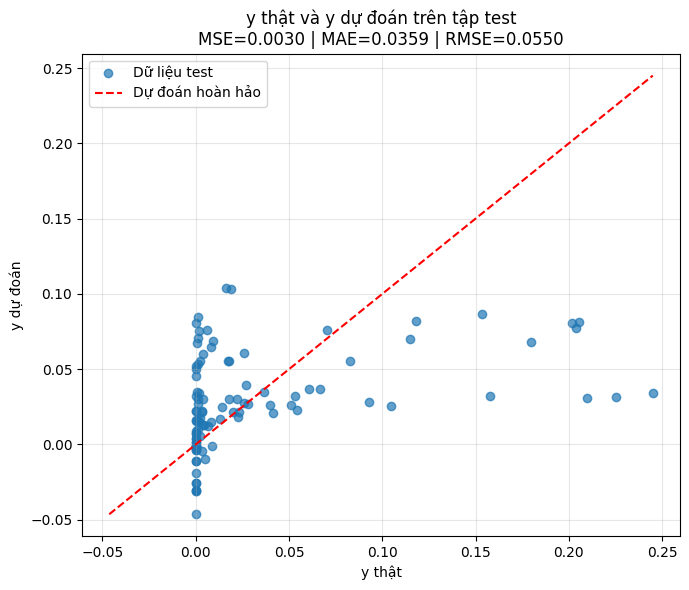

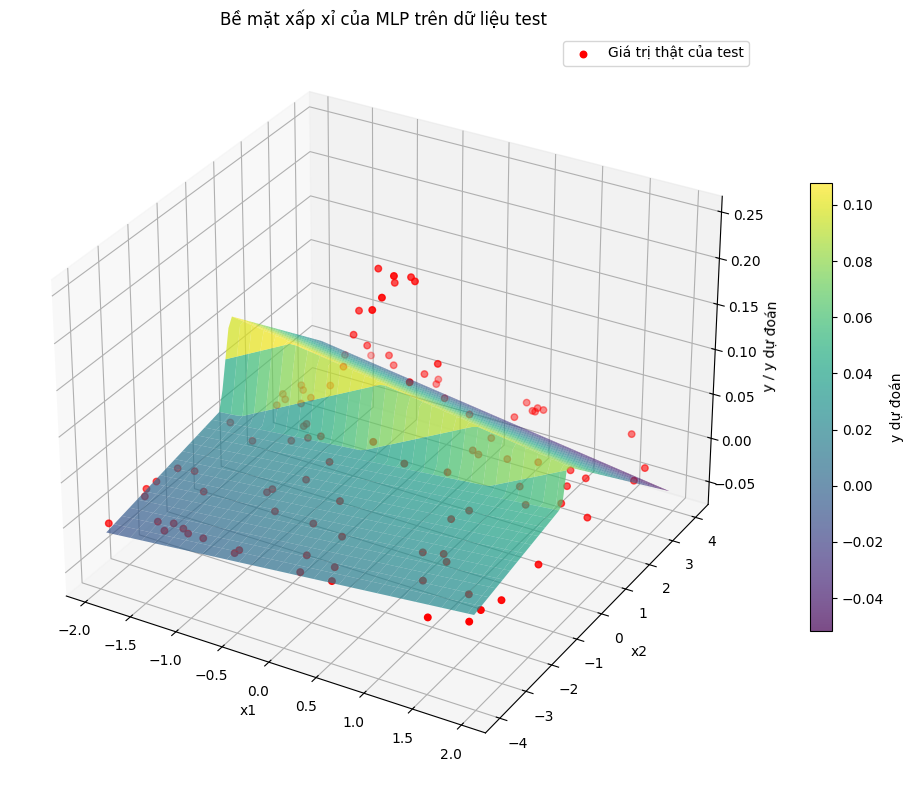

In [ ]:
import os
print("Thư mục hiện tại:", os.getcwd())
print(os.listdir())

# test
# tải model với min_val để chạy test
checkpoint = torch.load(
    "best_model.pth",
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
with torch.no_grad():
  y_test_pred = model(X_test_tensor).squeeze(-1)

  test_mse = criterion(y_test_pred, y_test_tensor).item()

  test_mae = torch.mean(
        torch.abs(y_test_pred - y_test_tensor)
    ).item()

  test_rmse = np.sqrt(test_mse)
print(f"Test MSE  : {test_mse:.6f}")
print(f"Test MAE  : {test_mae:.6f}")
print(f"Test RMSE : {test_rmse:.6f}")
# chuẩn bị vẽ hình
y_true = y_test_tensor.numpy().ravel()
y_pred = y_test_pred.cpu().numpy().ravel()
print("số lượng test: ",len(y_true))

# hình so sánh giữa y_true và y_pred
plt.figure(figsize=(7, 6))
plt.scatter(
    y_true,
    y_pred,
    alpha=0.7,
    label="Dữ liệu test"
)

lower = min(y_true.min(), y_pred.min())
upper = max(y_true.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Dự đoán hoàn hảo"
)

plt.xlabel("y thật")
plt.ylabel("y dự đoán")
plt.title(
    f"y thật và y dự đoán trên tập test\n"
    f"MSE={test_mse:.4f} | MAE={test_mae:.4f} "
    f"| RMSE={test_rmse:.4f}"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# hình tạo lưới để kiểm tra xem mô hình có xấp sỉ được hàm Gaussian 2D không
# Tạo lưới giá trị x1, x2
x1_values = np.linspace(X_test_tensor.numpy()[:, 0].min(), X_test_tensor.numpy()[:, 0].max(), 60)
x2_values = np.linspace(X_test_tensor.numpy()[:, 1].min(), X_test_tensor.numpy()[:, 1].max(), 60)

X1_grid, X2_grid = np.meshgrid(x1_values, x2_values)

# Ghép thành các cặp đầu vào [x1, x2]
X_grid = np.column_stack([
    X1_grid.ravel(),
    X2_grid.ravel()
]).astype(np.float32)

X_grid_tensor = torch.tensor(
    X_grid,
    dtype=torch.float32
).to(device)

# MLP dự đoán trên toàn bộ lưới
model.eval()

with torch.no_grad():
    y_grid_pred = model(X_grid_tensor).cpu().numpy()

Y_grid = y_grid_pred.reshape(X1_grid.shape)

# Vẽ bề mặt và các điểm dữ liệu test
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

# bề mặt dự đoán của model
surface = ax.plot_surface(
    X1_grid,
    X2_grid,
    Y_grid,
    cmap="viridis",
    alpha=0.7,
    linewidth=0
)

ax.scatter(
    X_test_tensor.numpy()[:, 0],
    X_test_tensor.numpy()[:, 1],
    y_true,
    color="red",
    s=22,
    label="Giá trị thật của test"
)

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y / y dự đoán")
ax.set_title("Bề mặt xấp xỉ của MLP trên dữ liệu test")

fig.colorbar(surface, ax=ax, shrink=0.6, label="y dự đoán")
ax.legend()
plt.tight_layout()
plt.show()

2. Bắt đầu thí nghiệm (seed = 42, batch size = 32, epochs = 1000, optimizer = Adam, learning rate = 0.002, activation = ReLU)


In [ ]:
def data_split_and_to_tensor(X, y):
  X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size = 0.1,
    random_state=42
  )
  X_train, X_val, y_train, y_val = train_test_split(
      X_temp, y_temp,
      test_size = 0.2,
      random_state=42
  )
  X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
  y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

  X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
  y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

  X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
  y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

  train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

  train_loader = DataLoader(
      train_dataset,
      batch_size=32, # 1 batch và toàn bộ data
      shuffle=True
  )
  print("X_train: ",len(X_train_tensor))
  print("y_train: ",len(y_train_tensor))
  print("X_val: ",len(X_val_tensor))
  print("y_val: ",len(y_val_tensor))
  print("X_test: ",len(X_test_tensor))
  print("y_test: ",len(y_test_tensor))
  return X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor, X_test_tensor, y_test_tensor, train_loader

# Chuyển tensor hoặc giá trị số về float
def to_float(value):
    if isinstance(value, torch.Tensor):
        return value.item()
    return float(value)

def evaluate(model, file, X_test, y_test):
    checkpoint = torch.load(file, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    with torch.no_grad():
        pred = model(X_test.to(device)).squeeze(-1).cpu()

    err = pred - y_test
    mse = (err ** 2).mean().item()
    return {"test_mse": mse, "test_rmse": mse ** 0.5, "test_mae": err.abs().mean().item()}

In [ ]:
# tạo dữ liệu huấn luyện và kiểm tra cho các thí nghiệm
np.random.seed(42)
torch.manual_seed(42)

x1_all, x2_all, y_all = gen_data_set(3000)
X_all = np.column_stack([
    x1_all.ravel(),
    x2_all.ravel()
]).astype(np.float32)

y_all = np.asarray(y_all).reshape(-1).astype(np.float32)
rng = np.random.default_rng(42)
indices = rng.permutation(len(y_all))

X_all = X_all[indices]
y_all = y_all[indices]

print("Kích thước X:", X_all.shape)
print("Kích thước y:", y_all.shape)

3000
x:  [[-0.50183952  1.38162395]
 [ 1.80285723  2.37345118]
 [ 0.92797577 -1.99625681]
 [ 0.39463394  0.9989928 ]
 [-1.37592544  0.57396787]
 [-1.37602192  2.66264301]
 [-1.76766555  3.24869648]
 [ 1.46470458 -3.90274583]
 [ 0.40446005  1.39215935]
 [ 0.83229031 -3.58531361]]
Y:  [1.55656189e-01 4.93640955e-09 5.87278643e-02 6.40027432e-02
 3.23082434e-03 1.08116141e-02 1.41596865e-03 3.01524027e-03
 3.28643293e-02 1.06915538e-02]
Kích thước X: (3000, 2)
Kích thước y: (3000,)


In [ ]:
# Thí nghiệm A: hiden layer = 1, perceptron = 3
cau_hinh_data = [278, 556, 834, 1112, 1389, 1667, 1945, 2223, 2500, 2778]
def exp_A(n):
  # khai báo tham số model
  torch.manual_seed(42)
  model_expA = MLP().to(device)
  criterion_expA = nn.MSELoss()
  optimizer_expA = torch.optim.Adam(model_expA.parameters(), lr=0.002)

  # chuẩn bị dữ liệu
  X = X_all[:n]
  y = y_all[:n]
  # chia dữ liệu
  X_train_tensor, y_train_tensor, X_val_tensor, y_val_tensor, X_test_tensor, y_test_tensor, train_loader = data_split_and_to_tensor(X, y)

  # huấn luyện và đánh giá lưu vào output(map) dùng để vẽ
  file = f"best_A{n}.pth"
  output = Train(train_loader, X_val_tensor, y_val_tensor, model_expA, optimizer_expA, criterion_expA, file, 1000)
  output.update(evaluate(model_expA, file, X_test_tensor, y_test_tensor))
  output["A"] = len(y_train_tensor)
  return output

res = []
for n in cau_hinh_data:
  res.append(exp_A(n))
print(res)

X_train:  200
y_train:  200
X_val:  50
y_val:  50
X_test:  28
y_test:  28
Epoch 100, Loss: 0.003089, Validation MSE: 0.002669
Đã lưu checkpoint 100
Epoch 200, Loss: 0.002550, Validation MSE: 0.002613
Epoch 300, Loss: 0.002387, Validation MSE: 0.002617
Epoch 400, Loss: 0.002338, Validation MSE: 0.002709
Epoch 500, Loss: 0.002312, Validation MSE: 0.002757
Epoch 600, Loss: 0.002307, Validation MSE: 0.002791
Epoch 700, Loss: 0.002287, Validation MSE: 0.002768
Epoch 800, Loss: 0.002293, Validation MSE: 0.002770
Epoch 900, Loss: 0.002287, Validation MSE: 0.002779
Epoch 1000, Loss: 0.002290, Validation MSE: 0.002764
X_train:  400
y_train:  400
X_val:  100
y_val:  100
X_test:  56
y_test:  56
Epoch 100, Loss: 0.002513, Validation MSE: 0.002352
Đã lưu checkpoint 100
Epoch 200, Loss: 0.002386, Validation MSE: 0.002118
Epoch 300, Loss: 0.002378, Validation MSE: 0.002103
Epoch 400, Loss: 0.002401, Validation MSE: 0.002194
Epoch 500, Loss: 0.002396, Validation MSE: 0.002107
Epoch 600, Loss: 0.002409

BẢNG ĐÁNH GIÁ THÍ NGHIỆM A


,A,MSE,MAE,RMSE
0,200,0.002770,0.037812,0.052630
1,400,0.002474,0.031522,0.049735
2,600,0.003226,0.038350,0.056796
3,800,0.002422,0.034514,0.049218
4,1000,0.002423,0.031386,0.049225
5,1200,0.001924,0.028667,0.043866
6,1400,0.002040,0.028362,0.045170
7,1600,0.002037,0.030507,0.045136
8,1800,0.000848,0.020923,0.029125
9,2000,0.001468,0.026326,0.038315


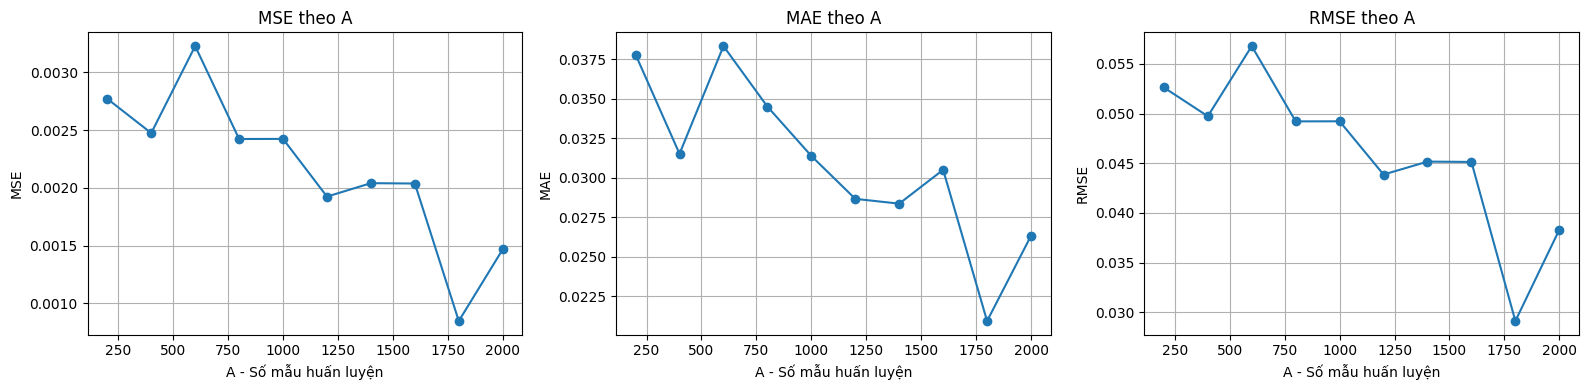

In [ ]:
# Bảng MSE/MAE hoặc RMSE; đồ thị sai số theo A;
df_expA = pd.DataFrame(res)
df_expA = df_expA.sort_values("A").reset_index(drop=True)
bang_ket_qua = df_expA[
    ["A", "test_mse", "test_mae", "test_rmse"]
].rename(columns={
    "test_mse": "MSE",
    "test_mae": "MAE",
    "test_rmse": "RMSE"
})

print("BẢNG ĐÁNH GIÁ THÍ NGHIỆM A")
display(bang_ket_qua.round(6))

# đồ thị sai số theo A
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metrics = [
    ("test_mse", "MSE"),
    ("test_mae", "MAE"),
    ("test_rmse", "RMSE")
]

for ax, (col, name) in zip(axes, metrics):
    ax.plot(df_expA["A"], df_expA[col], marker="o")
    ax.set_xlabel("A - Số mẫu huấn luyện")
    ax.set_ylabel(name)
    ax.set_title(f"{name} theo A")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
cau_hinh_perceptron = [1,2,3,4,5,6,7,8,9,10]

data_ = 1000

X_B = X_all[:data_]
y_B = y_all[:data_]

X_train_tensor_B, y_train_tensor_B, X_val_tensor_B, y_val_tensor_B, X_test_tensor_B, y_test_tensor_B, train_loader_B = data_split_and_to_tensor(X_B, y_B)

def exp_B(n):
  data_ = 1000
  # khai báo tham số model
  torch.manual_seed(42)
  model_expB = MLP(hiden_sizes = [n]).to(device)
  criterion_expB = nn.MSELoss()
  optimizer_expB = torch.optim.Adam(model_expB.parameters(), lr=0.002)

  # huấn luyện và đánh giá lưu vào output(map) dùng để vẽ
  file = f"best_B{n}.pth"
  output = Train(train_loader_B, X_val_tensor_B, y_val_tensor_B, model_expB, optimizer_expB, criterion_expB, file, 1000)
  output.update(evaluate(model_expB, file, X_test_tensor_B, y_test_tensor_B))
  output["B"] = n
  output["total_data"] = data_
  return output

res_B = []
for n in cau_hinh_perceptron:
  print("số perceptron cho mô hình: ",n)
  res_B.append(exp_B(n))
print(res_B)

X_train:  720
y_train:  720
X_val:  180
y_val:  180
X_test:  100
y_test:  100
số perceptron cho mô hình:  1
Epoch 100, Loss: 0.003192, Validation MSE: 0.003120
Epoch 200, Loss: 0.003190, Validation MSE: 0.003125
Epoch 300, Loss: 0.003196, Validation MSE: 0.003125
Epoch 400, Loss: 0.003195, Validation MSE: 0.003116
Epoch 500, Loss: 0.003199, Validation MSE: 0.003114
Epoch 600, Loss: 0.003194, Validation MSE: 0.003121
Epoch 700, Loss: 0.003200, Validation MSE: 0.003119
Epoch 800, Loss: 0.003203, Validation MSE: 0.003120
Epoch 900, Loss: 0.003201, Validation MSE: 0.003119
Epoch 1000, Loss: 0.003192, Validation MSE: 0.003117
số perceptron cho mô hình:  2
Epoch 100, Loss: 0.002861, Validation MSE: 0.002692
Epoch 200, Loss: 0.002769, Validation MSE: 0.002633
Epoch 300, Loss: 0.002763, Validation MSE: 0.002627
Epoch 400, Loss: 0.002750, Validation MSE: 0.002640
Epoch 500, Loss: 0.002229, Validation MSE: 0.002136
Đã lưu checkpoint 500
Epoch 600, Loss: 0.001844, Validation MSE: 0.001740
Epoch 7

BẢNG SO SÁNH THÍ NGHIỆM B


,B,Best epoch,Train MSE,Validation MSE,Test MSE,Test MAE,Test RMSE
0,1,599,0.003195,0.003114,0.004254,0.043989,0.065222
1,2,914,0.001833,0.001694,0.002463,0.033689,0.049632
2,3,999,0.002182,0.002136,0.002993,0.036742,0.054705
3,4,995,0.000261,0.000311,0.000316,0.011926,0.017780
4,5,866,0.000888,0.000857,0.001067,0.024442,0.032660
5,6,966,0.000802,0.000824,0.001091,0.024747,0.033025
6,7,929,0.000112,0.000119,0.000145,0.008320,0.012024
7,8,983,0.000245,0.000267,0.000265,0.011559,0.016289
8,9,962,0.000080,0.000083,0.000099,0.007290,0.009974
9,10,367,0.000142,0.000128,0.000140,0.009474,0.011850


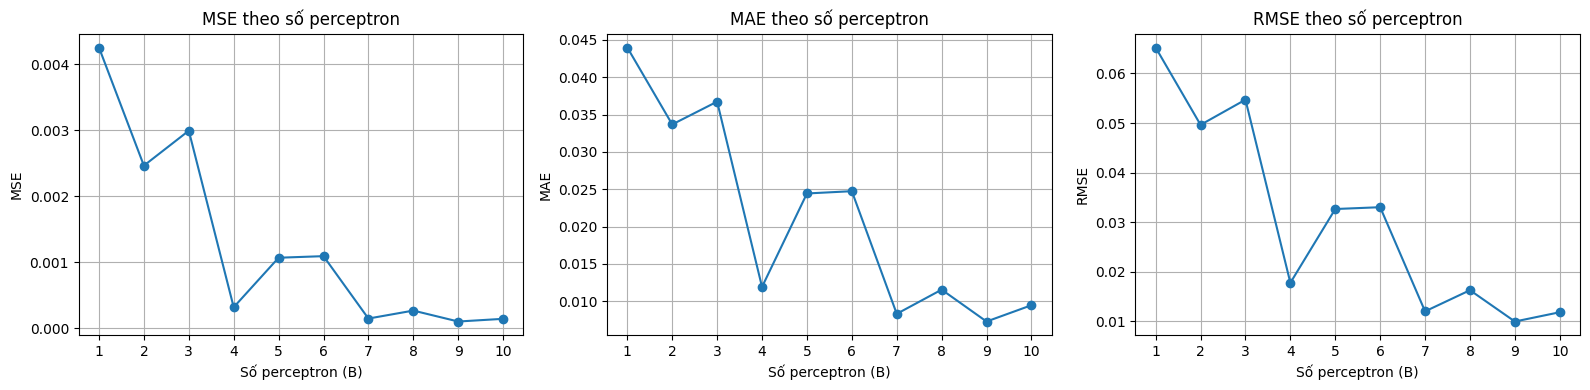

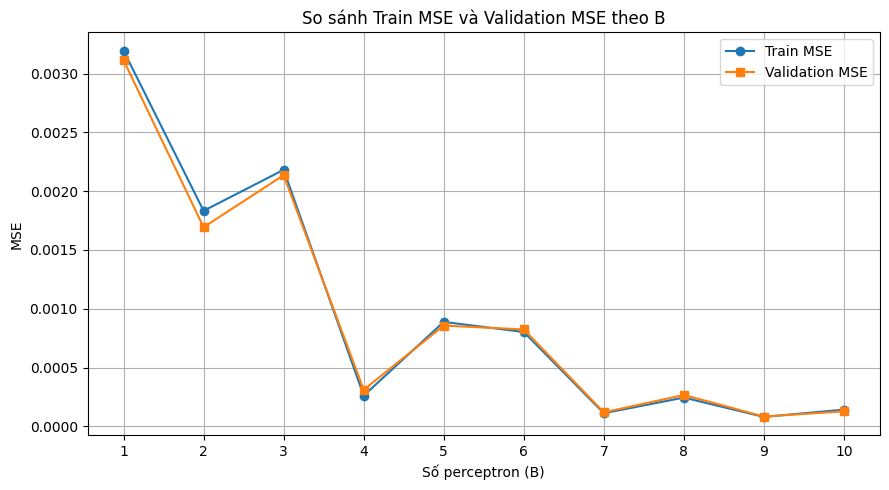

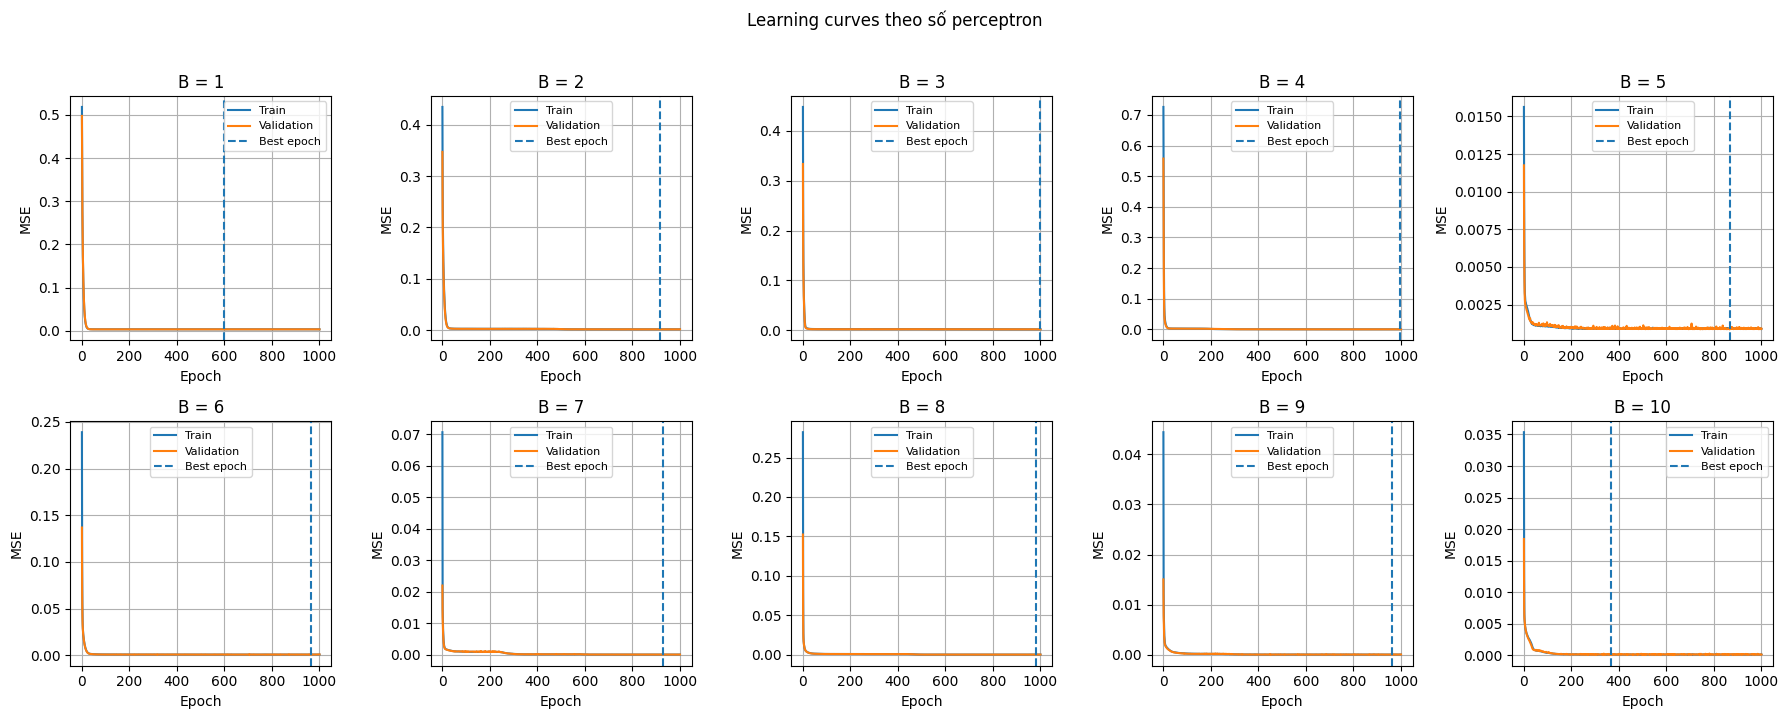

In [ ]:


# Tổng hợp kết quả từng cấu hình B
rows = []

for r in res_B:
    history = r["history"]
    best_epoch = int(r["best_epoch"])
    best_idx = best_epoch - 1

    train_history = [
        to_float(v) for v in history["train"]
    ]
    val_history = [
        to_float(v) for v in history["val"]
    ]

    rows.append({
        "B": r["B"],
        "Best epoch": best_epoch,
        "Train MSE": train_history[best_idx],
        "Validation MSE": val_history[best_idx],
        "Test MSE": to_float(r["test_mse"]),
        "Test MAE": to_float(r["test_mae"]),
        "Test RMSE": to_float(r["test_rmse"])
    })

df_B = pd.DataFrame(rows).sort_values("B").reset_index(drop=True)

print("BẢNG SO SÁNH THÍ NGHIỆM B")
display(df_B.round(6))

# vẽ đồ thị so sánh các chỉ số metrics giữa các perceptron
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = [
    ("Test MSE", "MSE"),
    ("Test MAE", "MAE"),
    ("Test RMSE", "RMSE")
]

for ax, (column, metric) in zip(axes, metrics):
    ax.plot(
        df_B["B"],
        df_B[column],
        marker="o"
    )

    ax.set_xlabel("Số perceptron (B)")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} theo số perceptron")
    ax.set_xticks(df_B["B"])
    ax.grid(True)

plt.tight_layout()
plt.show()

# vẽ đồ thị so sánh Train MSE và Validation MSE giữa các perceptron
plt.figure(figsize=(9, 5))

plt.plot(
    df_B["B"],
    df_B["Train MSE"],
    marker="o",
    label="Train MSE"
)

plt.plot(
    df_B["B"],
    df_B["Validation MSE"],
    marker="s",
    label="Validation MSE"
)

plt.xlabel("Số perceptron (B)")
plt.ylabel("MSE")
plt.title("So sánh Train MSE và Validation MSE theo B")
plt.xticks(df_B["B"])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# vẽ Learning curves theo số perceptron
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.ravel()

for i, r in enumerate(sorted(res_B, key=lambda x: x["B"])):
    train_loss = [
        to_float(v) for v in r["history"]["train"]
    ]

    val_loss = [
        to_float(v) for v in r["history"]["val"]
    ]

    epochs = range(1, len(train_loss) + 1)

    axes[i].plot(epochs, train_loss, label="Train")
    axes[i].plot(epochs, val_loss, label="Validation")

    axes[i].axvline(
        r["best_epoch"],
        linestyle="--",
        label="Best epoch"
    )

    axes[i].set_title(f'B = {r["B"]}')
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE")
    axes[i].grid(True)
    axes[i].legend(fontsize=8)

plt.suptitle("Learning curves theo số perceptron", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
cau_hinh_hiden_layer = [1,2,3,4]

data_ = 1000

X_C = X_all[:data_]
y_C = y_all[:data_]

X_train_tensor_C, y_train_tensor_C, X_val_tensor_C, y_val_tensor_C, X_test_tensor_C, y_test_tensor_C, train_loader_C = data_split_and_to_tensor(X_C, y_C)

def exp_c(n):
  data_ = 1000
  # khai báo tham số model
  torch.manual_seed(42)
  hiden_sizes = []
  for i in range(n):
    hiden_sizes.append(3)

  model_expC = MLP(hiden_sizes = hiden_sizes).to(device)
  criterion_expC = nn.MSELoss()
  optimizer_expC = torch.optim.Adam(model_expC.parameters(), lr=0.002)

  # huấn luyện và đánh giá lưu vào output(map) dùng để vẽ
  file = f"best_C{n}.pth"

  # đo thời gian
  start_time = time.perf_counter()

  output = Train(train_loader_C, X_val_tensor_C, y_val_tensor_C, model_expC, optimizer_expC, criterion_expC, file, 1000)

  train_time = time.perf_counter() - start_time

  output.update(evaluate(model_expC, file, X_test_tensor_C, y_test_tensor_C))
  output["C"] = n
  output["total_data"] = data_
  output["train_time_sec"] = train_time
  return output

res_C = []
for n in cau_hinh_hiden_layer:
  print("số hiden_layer cho mô hình: ",n)
  res_C.append(exp_c(n))
print(res_C)

X_train:  720
y_train:  720
X_val:  180
y_val:  180
X_test:  100
y_test:  100
số hiden_layer cho mô hình:  1
Epoch 100, Loss: 0.002598, Validation MSE: 0.002364
Epoch 200, Loss: 0.002571, Validation MSE: 0.002353
Epoch 300, Loss: 0.002551, Validation MSE: 0.002369
Epoch 400, Loss: 0.002550, Validation MSE: 0.002413
Epoch 500, Loss: 0.002580, Validation MSE: 0.002370
Epoch 600, Loss: 0.002442, Validation MSE: 0.002311
Epoch 700, Loss: 0.002430, Validation MSE: 0.002311
Epoch 800, Loss: 0.002446, Validation MSE: 0.002290
Epoch 900, Loss: 0.002468, Validation MSE: 0.002284
Epoch 1000, Loss: 0.002203, Validation MSE: 0.002156
số hiden_layer cho mô hình:  2
Epoch 100, Loss: 0.002412, Validation MSE: 0.002282
Epoch 200, Loss: 0.000887, Validation MSE: 0.000891
Epoch 300, Loss: 0.000851, Validation MSE: 0.000843
Đã lưu checkpoint 300
Epoch 400, Loss: 0.000897, Validation MSE: 0.000914
Epoch 500, Loss: 0.000829, Validation MSE: 0.000850
Epoch 600, Loss: 0.000789, Validation MSE: 0.000815
Epoch

BẢNG SO SÁNH THÍ NGHIỆM C


,Hidden layers,Neurons/layer,Best epoch,Train MSE,Validation MSE,Test MSE,Test MAE,Test RMSE,Training time (s)
0,1,3,999,0.002182,0.002136,0.002993,0.036742,0.054705,19.131914
1,2,3,983,0.000756,0.000786,0.001032,0.021089,0.032132,22.513549
2,3,3,746,0.000012,0.000012,0.000015,0.002620,0.003894,25.564618
3,4,3,783,0.000049,0.000050,0.000052,0.004885,0.007211,27.483396


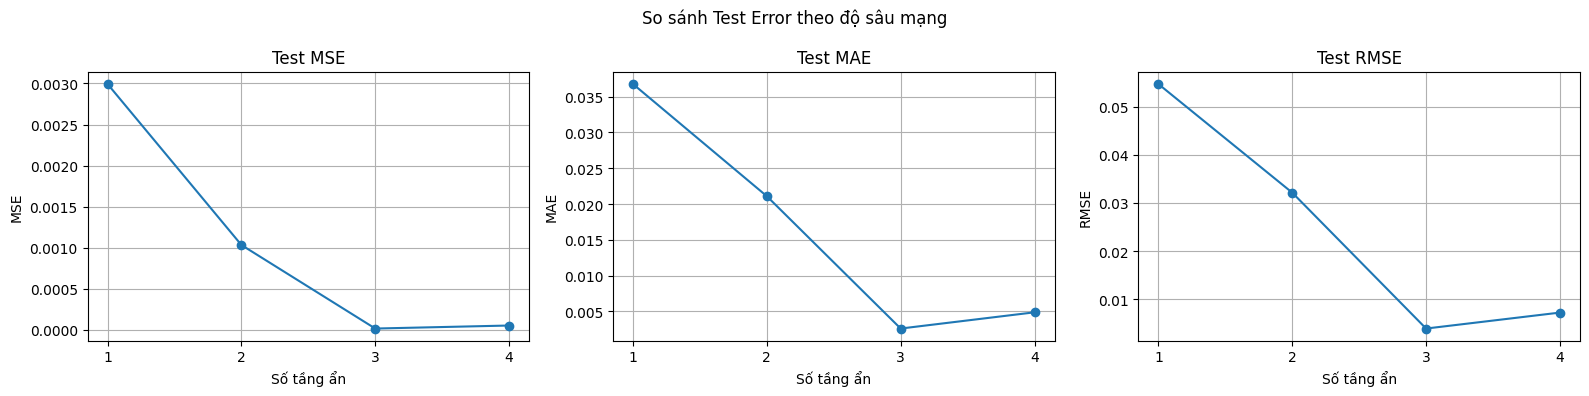

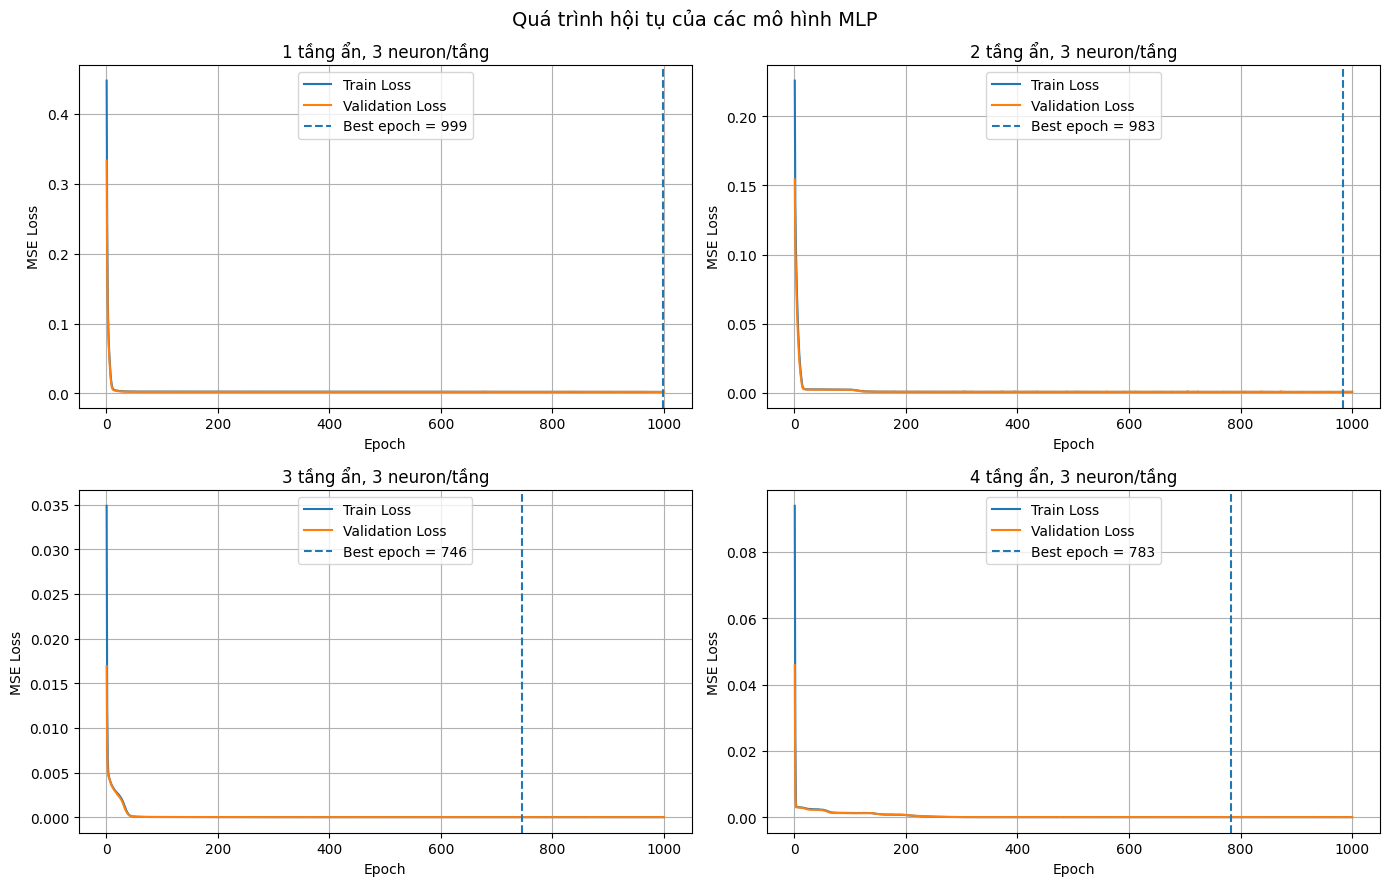

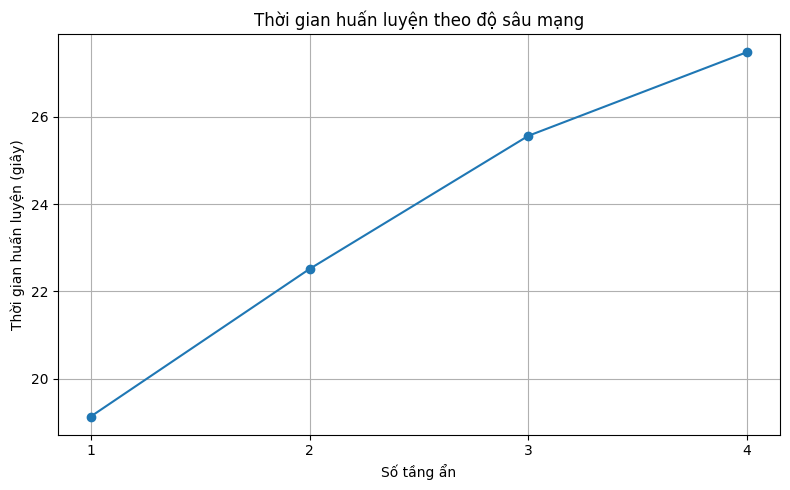

In [ ]:
rows = []

for r in res_C:
    best_epoch = int(r["best_epoch"])
    idx = best_epoch - 1

    train_history = r["history"]["train"]
    val_history = r["history"]["val"]

    rows.append({
        "Hidden layers": r["C"],
        "Neurons/layer": 3,
        "Best epoch": best_epoch,
        "Train MSE": to_float(train_history[idx]),
        "Validation MSE": to_float(val_history[idx]),
        "Test MSE": to_float(r["test_mse"]),
        "Test MAE": to_float(r["test_mae"]),
        "Test RMSE": to_float(r["test_rmse"]),
        "Training time (s)": r["train_time_sec"]
    })

df_C = pd.DataFrame(rows).sort_values("Hidden layers").reset_index(drop=True)

print("BẢNG SO SÁNH THÍ NGHIỆM C")
display(df_C.round(6))

# vẽ đồ thị so sánh metrics theo độ sâu mạng
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics = [
    ("Test MSE", "test_mse"),
    ("Test MAE", "test_mae"),
    ("Test RMSE", "test_rmse")
]

for ax, (title, key) in zip(axes, metrics):
    values = [to_float(r[key]) for r in sorted(res_C, key=lambda x: x["C"])]
    depths = sorted([r["C"] for r in res_C])

    ax.plot(depths, values, marker="o")
    ax.set_title(title)
    ax.set_xlabel("Số tầng ẩn")
    ax.set_ylabel(title.replace("Test ", ""))
    ax.set_xticks(depths)
    ax.grid(True)

plt.suptitle("So sánh Test Error theo độ sâu mạng")
plt.tight_layout()
plt.show()

# vẽ Learning curves theo độ sâu mạng
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, r in zip(axes, sorted(res_C, key=lambda x: x["C"])):
    train_loss = [to_float(v) for v in r["history"]["train"]]
    val_loss = [to_float(v) for v in r["history"]["val"]]
    epochs = range(1, len(train_loss) + 1)

    ax.plot(epochs, train_loss, label="Train Loss")
    ax.plot(epochs, val_loss, label="Validation Loss")

    ax.axvline(
        r["best_epoch"],
        linestyle="--",
        label=f'Best epoch = {r["best_epoch"]}'
    )

    ax.set_title(f'{r["C"]} tầng ẩn, 3 neuron/tầng')
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.grid(True)
    ax.legend()

plt.suptitle("Quá trình hội tụ của các mô hình MLP", fontsize=14)
plt.tight_layout()
plt.show()

# Vẽ đồ thị thời gian huấn luyện
df_time = df_C.sort_values("Hidden layers")

plt.figure(figsize=(8, 5))

plt.plot(
    df_time["Hidden layers"],
    df_time["Training time (s)"],
    marker="o"
)

plt.xlabel("Số tầng ẩn")
plt.ylabel("Thời gian huấn luyện (giây)")
plt.title("Thời gian huấn luyện theo độ sâu mạng")
plt.xticks(df_time["Hidden layers"])
plt.grid(True)
plt.tight_layout()
plt.show()